# Data Scaling in Neural Networks

> Ensuring all input features live on a comparable scale is one of the most important — and most overlooked — preprocessing steps in training neural networks.

---

## The Problem

Consider a dataset with two features: **age** and **salary**.

| Feature | Typical Range |
|---|---|
| Age | 20 – 80 |
| Salary | 30,000 – 150,000 |

These features differ in scale by a factor of ~1000. When passed directly into a neural network, this mismatch causes serious training problems.

### Why Does This Break Training?

During **backpropagation**, the gradient with respect to each weight is proportional to the magnitude of its input feature. Since salary values are thousands of times larger than age values:

- The weight connected to **salary** receives **very large gradients** → updates aggressively
- The weight connected to **age** receives **very small gradients** → barely updates, or gets ignored entirely

This means the network's loss landscape is almost entirely dominated by one feature, and the other contributes almost nothing to learning.

---

## Geometric Intuition

Gradient descent on unscaled data produces an **elongated, skewed loss surface** — shaped like a narrow valley or ellipse.

**Unscaled data — skewed loss surface:**
```
Loss
 │          ╭────────────────────╮
 │        ╭─╯                    ╰─╮
 │      ╭─╯    ← gradient descent  ╰─╮
 │    ╭─╯      zigzags down slowly   ╰─╮
 │  ──╯                                ╰──
 └──────────────────────────────────────── weights
```

The optimizer bounces back and forth along the steep axis (salary) while making tiny progress along the shallow axis (age). This causes:
- **Slow convergence** — many more steps needed to reach the minimum
- **Oscillation** — the optimizer overshoots along the dominant feature's axis
- **Poor minima** — may settle into a suboptimal solution

**Scaled data — symmetric loss surface:**
```
Loss
 │        ╭───────╮
 │      ╭─╯       ╰─╮
 │    ╭─╯    ↓      ╰─╮
 │  ╭─╯   straight     ╰─╮
 │  ╰──────────────────────╯
 └──────────────────────────── weights
```

With scaled features, the loss surface is roughly circular — gradient descent moves directly toward the minimum in far fewer steps.

---

## Scaling Techniques

### 1. Min-Max Normalization (Normalization)

Rescales all values to a fixed range, typically $[0, 1]$.

$$x' = \frac{x - x_{min}}{x_{max} - x_{min}}$$

```python
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X_train)
```

** Use when:** Data has a known, bounded range (e.g., pixel values 0–255)  
** Avoid when:** Data has significant outliers — they compress all other values into a tiny range

---

### 2. Standardization (Z-score Normalization)

Rescales data to have **mean = 0** and **standard deviation = 1**.

$$x' = \frac{x - \mu}{\sigma}$$

```python
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)
```

** Use when:** Data is roughly Gaussian, or outliers are present  
** Most common choice** for neural networks in practice  
** Avoid when:** The original scale or zero-point carries meaning

---

### 3. Robust Scaling

Uses the **median** and **interquartile range (IQR)** instead of mean and std — highly resistant to outliers.

$$x' = \frac{x - \text{median}(x)}{\text{IQR}(x)}$$

```python
from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()
X_scaled = scaler.fit_transform(X_train)
```

** Use when:** Dataset contains significant outliers that shouldn't be removed

---

## Comparison of Scaling Methods

| Method | Formula | Output Range | Outlier Sensitive? | Best For |
|---|---|---|---|---|
| Min-Max | $(x - min) / (max - min)$ | $[0, 1]$ | ✅ Yes | Bounded data, CNNs (images) |
| Standardization | $(x - \mu) / \sigma$ | ~$[-3, 3]$ | Somewhat | General neural networks |
| Robust Scaling | $(x - median) / IQR$ | Varies | ❌ No | Data with outliers |

---

## Important Rules

**1. Fit on training data only — transform train and test separately:**
```python
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  # fit + transform
X_test_scaled  = scaler.transform(X_test)        # transform only — no refit!
```
Fitting on the test set causes **data leakage** — the scaler learns information from the future, making your evaluation unreliable.

**2. Scale the target variable too (for regression):**
```python
y_scaler = StandardScaler()
y_train_scaled = y_scaler.fit_transform(y_train.reshape(-1, 1))
```

**3. Inverse transform predictions back to the original scale:**
```python
y_pred_original = y_scaler.inverse_transform(y_pred)
```

---

## Advantages of Scaling

- Faster convergence — gradient descent reaches the minimum in fewer steps
- More stable training — prevents one feature from dominating weight updates
- Improves performance of activation functions (Sigmoid, Tanh saturate on large inputs)
- Works equally well regardless of feature units

## What Happens Without Scaling

- Slow or completely stalled training
- Gradient explosion or vanishing on certain weights
- Model heavily biased toward high-magnitude features
- Poor generalization on unseen data

---

## Key Takeaway

> **Always scale your input features before training a neural network.** When in doubt, use **StandardScaler** — it's robust, widely used, and works well with most architectures. Never fit the scaler on your test set.

In [1]:
import numpy as np
import pandas as pd

In [2]:
df = pd.read_csv('datasets/Social_Network_Ads.csv')

In [3]:
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [4]:
df = df.iloc[:,2:]
df.head()

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0


<Axes: xlabel='Age', ylabel='EstimatedSalary'>

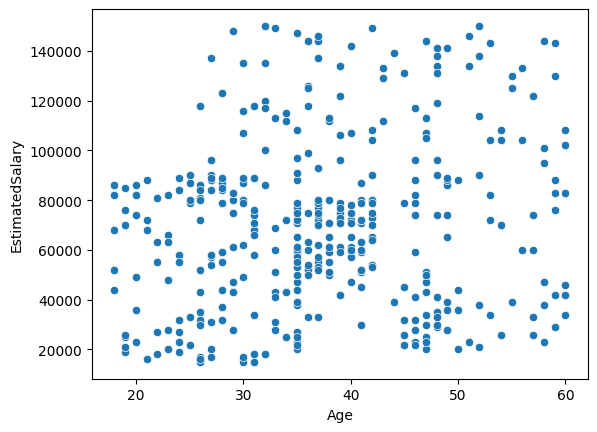

In [5]:
import seaborn as sns

sns.scatterplot(x=df.iloc[:, 0], y=df.iloc[:, 1])

In [6]:
X = df.iloc[:, 0:2]
y = df.iloc[:, -1]

In [7]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

In [8]:
model = Sequential()

model.add(Dense(128,activation='relu',input_dim=2))
model.add(Dense(1,activation='sigmoid'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [9]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 513 (2.00 KB)

 Trainable params: 513 (2.00 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=100)

Epoch 1/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 132ms/step - accuracy: 0.5969 - loss: 1188.4241 - val_accuracy: 0.3500 - val_loss: 532.1735
Epoch 2/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.4656 - loss: 334.0751 - val_accuracy: 0.6500 - val_loss: 209.3852
Epoch 3/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.4781 - loss: 131.1097 - val_accuracy: 0.6500 - val_loss: 62.6164
Epoch 4/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5219 - loss: 70.6368 - val_accuracy: 0.6500 - val_loss: 55.9350
Epoch 5/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.5594 - loss: 28.8577 - val_accuracy: 0.6500 - val_loss: 4.5755
Epoch 6/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.5031 - loss: 33.4521 - val_accuracy: 0.6500 - val_loss: 41.5522
Epoch 7/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5281 - loss: 39.5348 - val_accuracy: 0.3500 - val_loss: 39.1194
Epoch 8/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.4656 - loss: 53.73

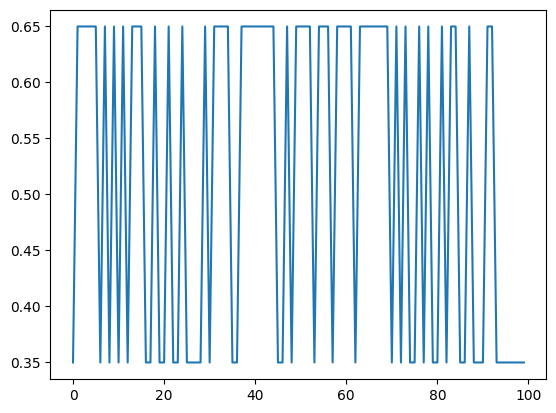

In [11]:
import matplotlib.pyplot as plt
plt.plot(history.history['val_accuracy'])

## It can be seen that validation accuracy is very unstable

In [12]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [13]:
X_train_scaled

array([[-1.06675246, -0.38634438],
       [ 0.79753468, -1.22993871],
       [ 0.11069205,  1.853544  ],
       [ 0.60129393, -0.90995465],
       [ 1.87685881, -1.28811763],
       [-0.57615058,  1.44629156],
       [ 0.3069328 , -0.53179168],
       [ 0.99377543,  0.10817643],
       [-1.16487283,  0.45724994],
       [-1.55735433,  0.31180264],
       [ 1.0918958 ,  0.45724994],
       [-0.18366908, -0.47361276],
       [ 0.20881242, -0.32816546],
       [ 0.3069328 ,  0.28271318],
       [-1.16487283, -1.57901222],
       [ 0.11069205,  0.25362372],
       [ 2.07309956,  1.73718616],
       [ 0.40505317, -0.18271817],
       [ 1.4843773 ,  2.11534913],
       [-0.37990983,  1.21357589],
       [ 1.87685881,  1.50447048],
       [ 0.11069205,  0.02090805],
       [ 0.89565505, -1.31720709],
       [-1.36111358, -1.49174384],
       [-0.18366908, -0.5899706 ],
       [-0.57615058,  2.31897535],
       [ 0.99377543, -1.20084925],
       [-0.77239133,  1.06812859],
       [ 2.17121993,

<Axes: >

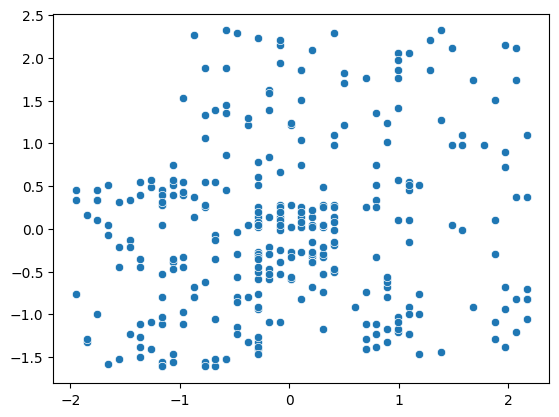

In [14]:
sns.scatterplot(x=X_train_scaled[:, 0], y=X_train_scaled[:, 1])

In [15]:
model = Sequential()

model.add(Dense(128, activation='relu', input_dim=2))
model.add(Dense(1, activation='sigmoid'))

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

history = model.fit(X_train_scaled, y_train, validation_data=(X_test_scaled, y_test), epochs=100)

Epoch 1/100


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.5531 - loss: 0.6932 - val_accuracy: 0.6125 - val_loss: 0.6634
Epoch 2/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7719 - loss: 0.6381 - val_accuracy: 0.8250 - val_loss: 0.6003
Epoch 3/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8188 - loss: 0.5925 - val_accuracy: 0.8625 - val_loss: 0.5446
Epoch 4/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.8438 - loss: 0.5527 - val_accuracy: 0.8750 - val_loss: 0.4965
Epoch 5/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8375 - loss: 0.5170 - val_accuracy: 0.8875 - val_loss: 0.4558
Epoch 6/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8406 - loss: 0.4859 - val_accuracy: 0.8875 - val_loss: 0.4207
Epoch 7/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8406 - loss: 0.4589 - val_accuracy: 0.9000 - val_loss: 0.3886
Epoch 8/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8500 - loss: 0.4354 - val_accuracy: 0.9125 - val_l

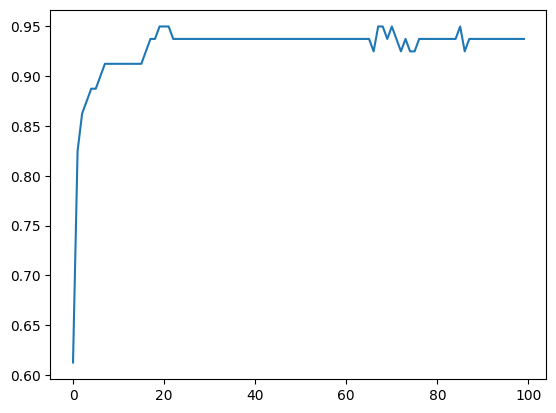

In [16]:
import matplotlib.pyplot as plt
plt.plot(history.history['val_accuracy'])

# It can be seen now that validation accuracy is stable